## Make the full lidar HD MNT by merging all tiles

In [1]:
import os
import sys

from matplotlib import colors

os.environ["PROJ_LIB"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["PROJ_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["GDAL_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/gdal"


import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rio
import pandas as pd

from rasterio.enums import Resampling

from pyproj import CRS

print(CRS.from_epsg(2154))

import rasterio
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge

EPSG:2154


In [2]:
# read some other data

gdf = gpd.read_file("../data/RNN_limite_poly_l93.shp")

gdf = gdf.set_crs("EPSG:2154")

In [3]:
mnt_dir = Path("../../PhenoAnalysis/data/MNT_lidarHD")

mnt_files = [
    p for p in mnt_dir.rglob("*")
    if p.is_file()
    and "_MNT_" in p.name
    and not p.name.endswith(".json")
]


for mnt in sorted(mnt_files):

    with rasterio.open(mnt) as src:

        print("\n", mnt.name)
        print("  CRS         :", src.crs)
        print("  Résolution  :", src.res)
        print("  Dimensions  :", src.width, "x", src.height)
        print("  Type        :", src.dtypes[0])
        print("  Bounds      :", src.bounds)


 LHD_FXX_0699_6153_MNT_O_0M50_LAMB93_IGN69
  CRS         : PROJCS["EPSG:2154",GEOGCS["unknown",DATUM["unnamed",SPHEROID["unretrievable - using WGS84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",46.5],PARAMETER["central_meridian",3],PARAMETER["standard_parallel_1",49],PARAMETER["standard_parallel_2",44],PARAMETER["false_easting",700000],PARAMETER["false_northing",6600000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
  Résolution  : (0.5, 0.5)
  Dimensions  : 2000 x 2000
  Type        : float32
  Bounds      : BoundingBox(left=698999.75, bottom=6152000.25, right=699999.75, top=6153000.25)

 LHD_FXX_0699_6154_MNT_O_0M50_LAMB93_IGN69
  CRS         : PROJCS["EPSG:2154",GEOGCS["unknown",DATUM["unnamed",SPHEROID["unretrievable - using WGS84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433

In [4]:
src_files = [
    rasterio.open(mnt)
    for mnt in sorted(mnt_files)
]

print(f"{len(src_files)} tuiles ouvertes")

34 tuiles ouvertes


In [5]:
# build the mnt (all tiles)

mnt_mosaic, mosaic_transform = merge(
    src_files,
    nodata=-9999
)

# merge() retourne un tableau de forme :
# (band, y, x)
mnt_mosaic = mnt_mosaic[0]

mnt_mosaic = mnt_mosaic.astype("float32")

mnt_mosaic[mnt_mosaic == -9999] = np.nan

print("\nMosaïque créée")
print("Shape :", mnt_mosaic.shape)
print("Nombre de pixels :", mnt_mosaic.size)


Mosaïque créée
Shape : (12000, 12000)
Nombre de pixels : 144000000


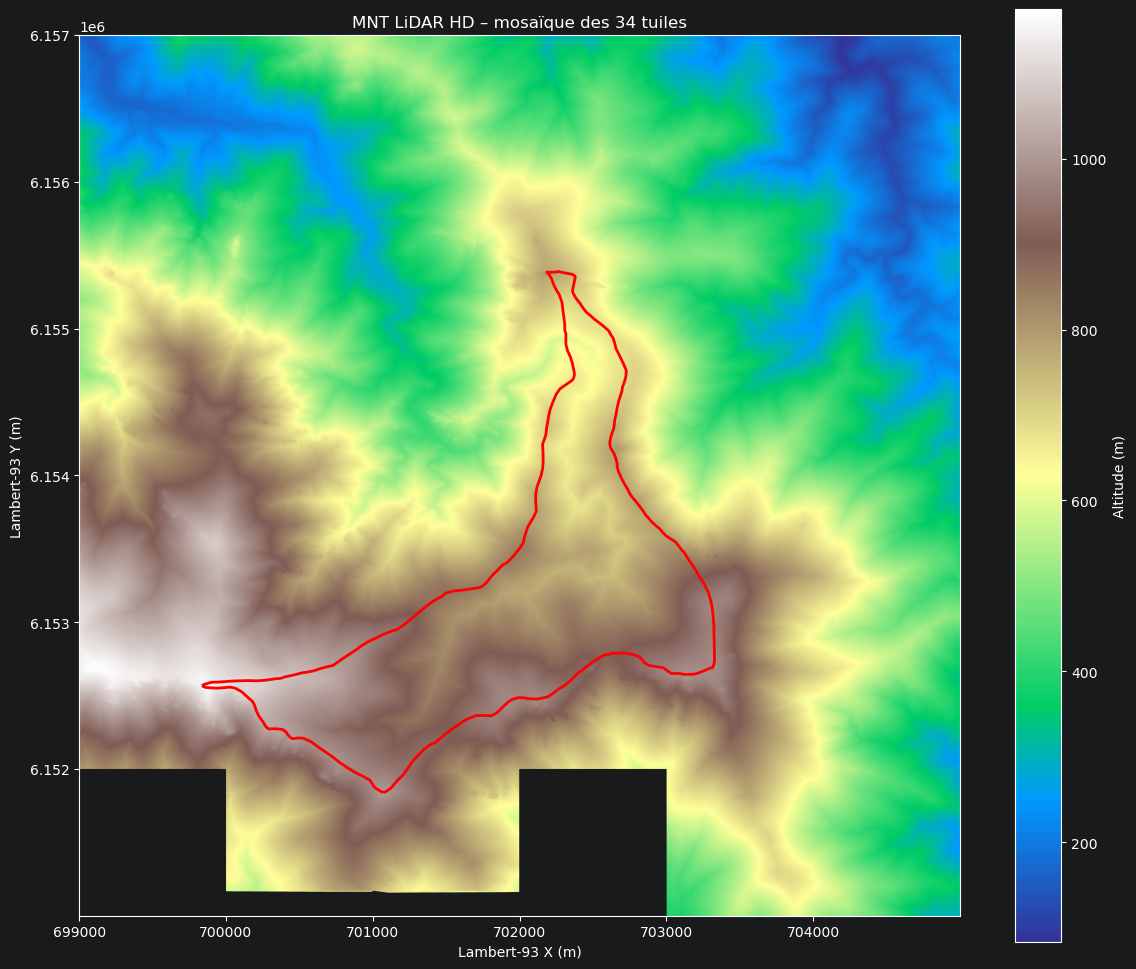

In [6]:
# plot and make sure everything is ok

from rasterio.plot import plotting_extent

fig, ax = plt.subplots(figsize=(12, 10))

# Emprise spatiale réelle du raster
extent = plotting_extent(
    mnt_mosaic,
    mosaic_transform
)

# Afficher le MNT
im = ax.imshow(
    mnt_mosaic,
    cmap="terrain",
    extent=extent
)

# Mettre le polygone dans le même CRS que le MNT
gdf_2154 = gdf.to_crs("EPSG:2154")

# Afficher le contour
gdf_2154.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

# Colorbar
fig.colorbar(
    im,
    ax=ax,
    label="Altitude (m)"
)

ax.set_title("MNT LiDAR HD – mosaïque des 34 tuiles")
ax.set_xlabel("Lambert-93 X (m)")
ax.set_ylabel("Lambert-93 Y (m)")

plt.tight_layout()
plt.show()

In [7]:
# ecrire le mnt complet dans un fichier
output_mnt = mnt_dir / "mnt_mosaic.tif"

profile = src_files[0].profile.copy()

profile.update(
    height=mnt_mosaic.shape[0],
    width=mnt_mosaic.shape[1],
    transform=mosaic_transform
)

with rasterio.open(output_mnt, "w", **profile) as dst:
    dst.write(np.nan_to_num(mnt_mosaic, nan=-9999), 1)